In [6]:
from fastai.data.external import untar_data
from fastai.vision.all import *


In [7]:
path = untar_data(URLs.PASCAL_2007)

<div><progress max="1637796771" value="1637801984"></progress> 100.00% [1637801984/1637796771 25:43&lt;00:00]</div>

In [8]:
import pandas as pd

In [9]:
df = pd.read_csv(path/'train.csv')

In [10]:
df.head()

,fname,labels,is_valid
0,000005.jpg,chair,True
1,000007.jpg,car,True
2,000009.jpg,horse person,True
3,000012.jpg,car,False
4,000016.jpg,bicycle,True


In [47]:
df

,fname,labels,is_valid
0,000005.jpg,chair,True
1,000007.jpg,car,True
2,000009.jpg,horse person,True
3,000012.jpg,car,False
4,000016.jpg,bicycle,True
...,...,...,...
5006,009954.jpg,horse person,True
5007,009955.jpg,boat,True
5008,009958.jpg,person bicycle,True
5009,009959.jpg,car,False


In [14]:
def get_x(r):
    return path/'train'/r['fname']

In [15]:
def get_y(r):
    return r['labels'].split(' ')

In [33]:
def splitter(df):
    train = df.index[~df['is_valid']].tolist()
    valid = df.index[df['is_valid']].tolist()
    return train,valid

In [34]:
dblock = DataBlock(
    blocks=(ImageBlock, MultiCategoryBlock),
    splitter=splitter,
    get_x=get_x,
    get_y=get_y
)

In [35]:
dsets = dblock.datasets(df)

In [44]:
len(dsets)

5011

In [50]:
dblock = DataBlock(
    blocks=(ImageBlock, MultiCategoryBlock),
    splitter=splitter,
    get_x=get_x,
    get_y=get_y,
    item_tfms=RandomResizedCrop(128, min_scale=0.35)
)

In [51]:
dls = dblock.dataloaders(df)

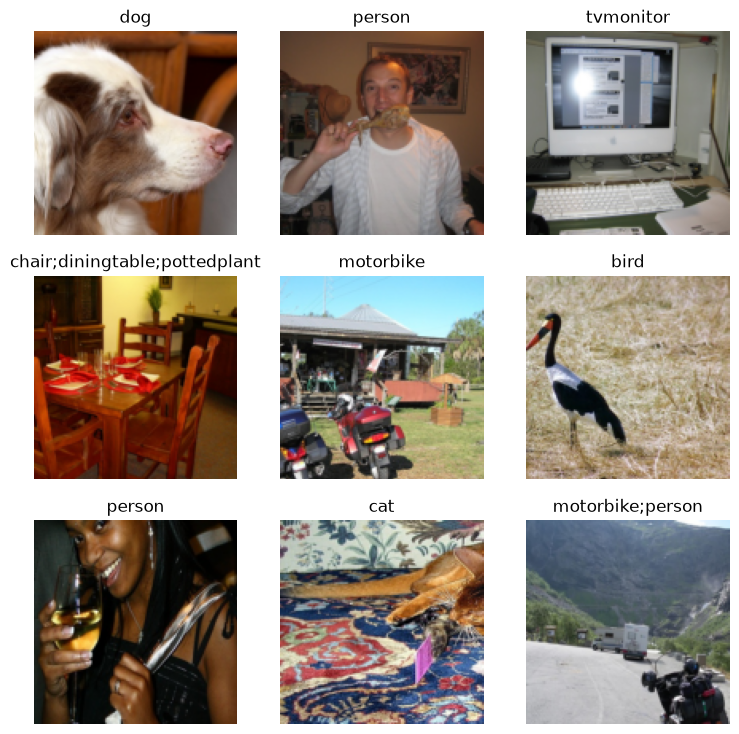

In [73]:
dls.show_batch()

In [74]:
from fastai.vision.learner import cnn_learner
from fastai.vision.learner import vision_learner
learn = cnn_learner(dls, resnet18)

In [75]:
learn.model = learn.model.cuda()

In [76]:
x,y = dls.train.one_batch()
activs = learn.model(x)
activs.shape

torch.Size([64, 20])

In [78]:
def accuracy_multi(inp, targ, thresh=0.5, sigmoid=True):
    if sigmoid:
        inp = inp.sigmoid()
    return ((inp>thresh)==targ.bool()).float().mean()

In [79]:
learn = cnn_learner(
    dls,
    resnet50,
    metrics=partial(accuracy_multi, thresh=0.2)
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Vidhy/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:55<00:00, 1.84MB/s]


In [80]:
learn.fine_tune(3, base_lr=3e-3, freeze_epochs=4)

epoch,train_loss,valid_loss,accuracy_multi,time
0,0.955062,0.720904,0.219980,00:37
1,0.833032,0.553304,0.278665,00:33
2,0.608210,0.195247,0.824343,00:30
3,0.361054,0.118654,0.947809,00:31


epoch,train_loss,valid_loss,accuracy_multi,time
0,0.125319,0.104240,0.953307,00:34
1,0.111844,0.097417,0.957630,00:35
2,0.097879,0.095370,0.958048,00:36


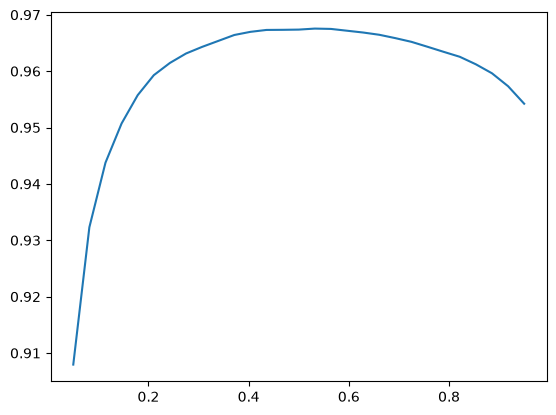

In [81]:
preds, targs = learn.get_preds()

xs = torch.linspace(0.05, 0.95, 29)

accs = [
    accuracy_multi(preds, targs, thresh=i, sigmoid=False)
    for i in xs
]

plt.plot(xs, accs)

REGRESSION  

In [83]:
path = untar_data(URLs.BIWI_HEAD_POSE)

<div><progress max="452316199" value="452321280"></progress> 100.00% [452321280/452316199 03:16&lt;00:00]</div>

In [84]:
img_files = get_image_files(path)

In [85]:
def img2pose(x):
    return Path(f'{str(x)[:-7]}pose.txt')

In [86]:
im = PILImage.create(img_files[0])

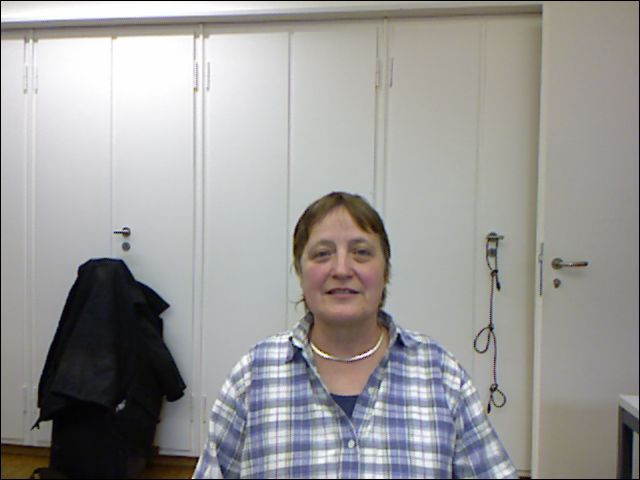

In [89]:
im


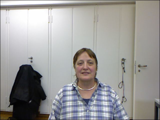

In [88]:
im.to_thumb(160)